# **Quiz: Piedra, papel o tijera con agentes**

En este quiz modelará el juego piedra, papel o tijera como un sistema de agentes que se mueven en una grilla. Cuando dos agentes coinciden en una celda, el ganador convierte al perdedor en un agente de su propio tipo: la piedra gana a la tijera, la tijera gana al papel y el papel gana a la piedra.

Use el notebook adjunto para trabajar en el quiz. Ahí hay un código inicial para completar.


1. Defina las clases **Piedra**, **Papel** y **Tijera**, que heredan de **Base**. En cada paso, el agente debe:
* moverse a una celda vecina
* convertir a su propio tipo a cada agente de su celda al que le gane.

_Sugerencia:_ use `isinstance(otro, Clase)` para saber de qué tipo es otro agente.

2. Cree un mundo con 50 agentes de cada tipo y `seed=0`. Ejecútelo durante 300 pasos e imprima cada 30 pasos cuántos agentes hay de cada tipo.

_Sugerencia:_ cuando un tipo de agente desaparece, puede no aparecer en _conteo()_. Use `conteo().get("Piedra", 0)` en lugar de `conteo()["Piedra"]`.

3. Responda:

    [a.] ¿Qué tipo de agente terminó dominando? ¿Cuál se había extinguido justo antes?

    [b.] ¿Por qué ganó ese tipo y no el que tenía más agentes en ese momento? Explique la relación entre la extinción y el resultado final.

    [c.] Repita la simulación con `seed=1` y `seed=2`. ¿Gana siempre el mismo tipo de agente? ¿Por qué?


In [1]:
%pip install mesa --q

/Volumes/SSD/World/External/Study/UR/AIPS-I/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import mesa


class Base(mesa.Agent):
    def mover(self):
        vecinos = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=False)
        self.model.grid.move_agent(self, self.random.choice(vecinos))

    def vecinos(self):
        """Otros agentes en la misma celda."""
        return [a for a in self.model.grid.get_cell_list_contents([self.pos]) if a is not self]

    def convertir(self, otro, NuevaClase):
        """Reemplaza al agente 'otro' por uno nuevo de NuevaClase en la misma celda."""
        pos = otro.pos
        self.model.grid.remove_agent(otro)
        otro.remove()
        self.model.grid.place_agent(NuevaClase(self.model), pos)


class Mundo(mesa.Model):
    def __init__(self, poblacion, lado=20, seed=None):
        super().__init__(rng=seed)
        self.grid = mesa.space.MultiGrid(lado, lado, torus=True)
        for Clase, n in poblacion.items():
            for _ in range(n):
                self.grid.place_agent(Clase(self), (self.random.randrange(lado),
                                                    self.random.randrange(lado)))

    def step(self):
        self.agents.shuffle_do("step")

    def conteo(self):
        return {c.__name__: len(a) for c, a in self.agents_by_type.items()}

In [ ]:
# 1. Agentes: cada uno se mueve y convierte a su propio tipo a quien le gana en su celda
#    La lógica es que Piedra > Tijera | Tijera > Papel | Papel > Piedra

class Piedra(Base):
    def step(self):
        self.mover()
        for otro in self.vecinos():
            if isinstance(otro, Tijera):
                self.convertir(otro, Piedra)


class Papel(Base):
    def step(self):
        self.mover()
        for otro in self.vecinos():
            if isinstance(otro, Piedra):
                self.convertir(otro, Papel)


class Tijera(Base):
    def step(self):
        self.mover()
        for otro in self.vecinos():
            if isinstance(otro, Papel):
                self.convertir(otro, Tijera)

In [ ]:
# 2. Mundo con 50 agentes de cada tipo, seed=0, 300 pasos, conteo cada 30
TIPOS = ["Piedra", "Papel", "Tijera"]

def simular(seed, pasos=300, cada=30):
    """Corre el mundo e imprime el conteo porcada paso. Voy a devolver el historial completo."""
    mundo = Mundo({Piedra: 50, Papel: 50, Tijera: 50}, seed=seed)
    historial = []
    for t in range(pasos + 1):
        c = mundo.conteo()
        historial.append({k: c.get(k, 0) for k in TIPOS})
        if t % cada == 0:
            print(f"Paso {t} | " + " | ".join(f"{k}: {historial[-1][k]:3d}" for k in TIPOS))
        if t < pasos:
            mundo.step()
    return historial

def extinciones(historial):
    """Paso en que cada tipo llega a cero por primera vez (None si sobrevive)."""
    return {k: next((t for t, c in enumerate(historial) if c[k] == 0), None) for k in TIPOS}

h0 = simular(seed=0)
print("\nExtinciones:", extinciones(h0))
print("Paso 196:", h0[196], "\nPaso 197:", h0[197])

Paso   0 | Piedra:  50 | Papel:  50 | Tijera:  50
Paso  30 | Piedra:  12 | Papel:  28 | Tijera: 110
Paso  60 | Piedra:  90 | Papel:  53 | Tijera:   7
Paso  90 | Piedra:   2 | Papel: 103 | Tijera:  45
Paso 120 | Piedra:  80 | Papel:  18 | Tijera:  52
Paso 150 | Piedra:  23 | Papel:  93 | Tijera:  34
Paso 180 | Piedra:  54 | Papel:   1 | Tijera:  95
Paso 210 | Piedra: 119 | Papel:  31 | Tijera:   0
Paso 240 | Piedra:   0 | Papel: 150 | Tijera:   0
Paso 270 | Piedra:   0 | Papel: 150 | Tijera:   0
Paso 300 | Piedra:   0 | Papel: 150 | Tijera:   0

Extinciones: {'Piedra': 240, 'Papel': None, 'Tijera': 197}
Paso 196: {'Piedra': 146, 'Papel': 3, 'Tijera': 1} 
Paso 197: {'Piedra': 146, 'Papel': 4, 'Tijera': 0}


## 3. Respuestas

**a.** Pues haciendo uso de `seed=0` el que terminó dominando fue el Papel, que alcanza la población completa de 150 agentes, como hasta por el paso 240 y se mantiene así hasta la final.

El tipo que se extinguió justo antes fue la **Tijera**.

La Piedra la última en desaparecer ya sin ninguna posibilidad de recuperarse.

**b.** Quisiera mencionar que al momento en que se extinguió la Tijera, la Piedra estaba ganándole ala mayoría, pero no logró concretar, dado que la Piedra sólo puede convertir Tijeras porque al desaparecer su única presa queda sin formas de crecer (jaja). Ahora, mientras que el Papel conserva a su presa y pues ya no tiene un depredador que lo amenazara.

De lo anterior pues podría enunciar la siguiente regla general: Cuando un tipo X se extingue, gana el tipo al que X le ganaba (la presa de X) porque pues se queda liberado de su único depredador, esto es algo del estilo "el enemigo de mi enemigo es mi amigo", je~.

También se observa que ir ganando al inicio no es garantía de nada, en el paso 30 la Tijera tenía como 100 agentes y fue justamente la primera en extinguirse, esto porque al crecer un tipo se alimenta a su depredador, generando por así decirlo cíclicas cada vez más amplias hasta que una fluctuación lleva a algún tipo a cero.

In [ ]:
# 3c. Repetición con seed=1 y seed=2
historiales = {0: h0}
for s in (1, 2):
    print(f"\n=== seed={s} ===")
    historiales[s] = simular(seed=s)
    print("Extinciones:", extinciones(historiales[s]))


===== seed=1 =====
Paso   0 | Piedra:  50 | Papel:  50 | Tijera:  50
Paso  30 | Piedra:  72 | Papel:  33 | Tijera:  45
Paso  60 | Piedra:  66 | Papel:  16 | Tijera:  68
Paso  90 | Piedra:  22 | Papel:  87 | Tijera:  41
Paso 120 | Piedra:  60 | Papel:   7 | Tijera:  83
Paso 150 | Piedra:  48 | Papel:  81 | Tijera:  21
Paso 180 | Piedra:  79 | Papel:  24 | Tijera:  47
Paso 210 | Piedra:  10 | Papel: 126 | Tijera:  14
Paso 240 | Piedra:  17 | Papel:   6 | Tijera: 127
Paso 270 | Piedra: 122 | Papel:  11 | Tijera:  17
Paso 300 | Piedra:   2 | Papel: 148 | Tijera:   0
Extinciones: {'Piedra': None, 'Papel': None, 'Tijera': 283}

===== seed=2 =====
Paso   0 | Piedra:  50 | Papel:  50 | Tijera:  50
Paso  30 | Piedra:  46 | Papel:  56 | Tijera:  48
Paso  60 | Piedra:  23 | Papel:  65 | Tijera:  62
Paso  90 | Piedra:  98 | Papel:  38 | Tijera:  14
Paso 120 | Piedra:   0 | Papel: 123 | Tijera:  27
Paso 150 | Piedra:   0 | Papel:   1 | Tijera: 149
Paso 180 | Piedra:   0 | Papel:   0 | Tijera: 150


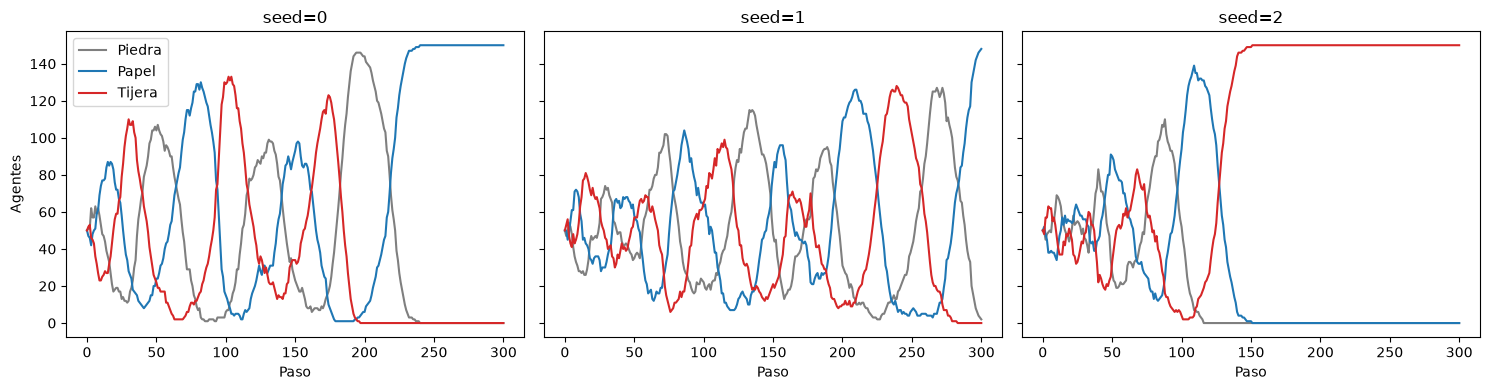

In [6]:
import matplotlib.pyplot as plt

colores = {"Piedra": "tab:gray", "Papel": "tab:blue", "Tijera": "tab:red"}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (s, h) in zip(ejes, historiales.items()):
    for k in TIPOS:
        ax.plot([c[k] for c in h], label=k, color=colores[k])
    ax.set_title(f"seed={s}")
    ax.set_xlabel("Paso")
ejes[0].set_ylabel("Agentes")
ejes[0].legend()
plt.tight_layout()
plt.show()

**c.** No, el ganador no es siempre el mismo:

- seed=2: Aquí la primera en extinguirse es la Piedra, con lo cual la Tijera queda sin depredador y gana: el Papel desaparece y la **Tijera** se queda con los 150 agentes.

Esto ocurre porque el juego es simétrico, así que ningún tipo tiene una ventaja intrínseca, el ganador queda determinado por cuál tipo se extingue primero, lo cual depende de fluctuaciones aleatorias como posiciones iniciales, movimientos y orden de activación del shuffle_do.
Que pues esto en una población finita y pequeña amplifican las oscilaciones hasta que alguna toque cero.

La semilla hace que cada corrida sea reproducible (misma semilla, mismo resultado), pero eso no favorece a ningún tipo, por lo que al cambiarla cambia la historia y con ella el ganador, aunque la quizás por la regla de "gana la presa del primero que se extingue" se cumple en las tres corridas.